# Exercise 01 — Statistical Graphs with Python

A dataset can contain thousands of values, making patterns difficult to recognise by reading a table. **Graphs translate those values into a visual form** so that we can compare measurements, identify changes and ask new questions. The type of graph matters because different representations reveal different aspects of the same data.

In this exercise, we will create three graphs:

- A **line graph** to follow galvanic skin response (GSR) readings through a recorded sequence.
- A **bar chart** to compare how frequently different tags appear in Flickr photographs.
- A **histogram** to examine the distribution of Flickr's geographical accuracy values.

We will use **Pandas** to organise the data, **Seaborn** to produce statistical plots and **Matplotlib** to control labels and save the figures. Seaborn builds on Matplotlib and works directly with Pandas DataFrames.

![Seaborn logo](https://seaborn.pydata.org/_static/logo-wide-lightbg.svg)

You can explore other graph types in the [Seaborn example gallery](https://seaborn.pydata.org/examples/index.html).

## Installation

If these libraries are not installed in your Python environment, run this command in a notebook cell:

```python
%pip install pandas seaborn matplotlib
```

The example datasets are stored in this exercise's `assets` folder. Run the notebook from its own folder so that the relative paths work.

## Line Graph — GSR Measurements

Our first dataset records measurements taken during a walk. **GSR** (galvanic skin response), also called electrodermal activity, relates to changes in the skin's electrical properties. The file also includes location and time information.

We will plot the `GSR` column against `Count`, which numbers the recorded samples. This shows **how the readings change over the sequence**, not their exact timing or location. We should not interpret individual peaks as specific emotions: without knowing the sensor's calibration and the conditions of recording, these values are simply the recorded sensor readings.

First, load the tab-separated file into a Pandas DataFrame:

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# The dataset is stored alongside this notebook
gsr_df = pd.read_csv("assets/010RC14X.CSV", sep="\t")

gsr_df.head()

In [ ]:
# A line graph follows each GSR reading in measurement order
sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(figsize=(10, 4))
sns.lineplot(
    data=gsr_df,
    x="Count",
    y="GSR",
    estimator=None,
    ax=ax
)

ax.set_title("GSR readings during a walk")
ax.set_xlabel("Measurement number")
ax.set_ylabel("GSR reading (sensor units)")

fig.tight_layout()
fig.savefig("lineplot.pdf")
plt.show()

The line connects readings in their recorded order. We use `estimator=None` so that Seaborn plots the individual observations rather than calculating an average for repeated x-values. The labels tell the reader what the axes represent; the units are left as **sensor units** because this example does not establish a calibration.

The command `fig.savefig("lineplot.pdf")` exports the graph as a vector PDF. This can be placed into **Adobe Illustrator or InDesign** for further graphic development.

**Alternative — Adobe Illustrator Graph:** Python is excellent for exploring data and producing a graph quickly, but you can create **much better-looking, carefully designed graphics** using the **Graph tools in Adobe Illustrator**. Export your data as a CSV, import or paste the values into an Illustrator graph, and refine its typography, line weights, colours and layout. This gives you more control over the final visual presentation while retaining a graph based on the underlying data.

The following code exports the GSR values for use in Illustrator:

In [ ]:
# Export the GSR values as a simple, one-column table
gsr_df[["GSR"]].to_csv("GSR.csv", index=False)

## Bar Chart — Most Common Flickr Tags

Our next example uses a collection of Flickr photographs. Each row represents a photograph and the `tags` column contains words supplied by users to describe it. We want to know: **which tags occur most often in the dataset?**

A **bar chart** is useful because tags are categories rather than continuous measurements. We first need to transform the text into a table of frequencies.

Load the CSV file and inspect its first rows:

In [ ]:
# Read the Flickr dataset from the assets folder
flickr_df = pd.read_csv("assets/Flickr.csv")

flickr_df[["title", "tags"]].head(3)

### From tags to frequencies

A photograph may have several tags separated by spaces, for example `signs london olympus lee`. Pandas can turn these strings into individual values in three steps:

1. **`.str.split()`** separates each string into a list of tags.
2. **`.explode()`** turns those lists into individual rows, one per tag.
3. **`.value_counts()`** counts the number of times each tag appears and sorts the results from most to least frequent.

![Diagram of the steps from Flickr tags to frequency counts](assets/flickr-tag-counts.svg)

One photograph can contribute several tags. Therefore, these values count **tag occurrences**, not the number of photographs in the collection.

We'll show the **20 most common tags**. Using `.head(20)` includes the most frequent tag; the earlier example using `.iloc[1:40]` accidentally skipped it.

In [ ]:
# Convert each space-separated tag string into a list
tag_lists = flickr_df["tags"].fillna("").str.split()

# Put each tag on its own row, then count occurrences
individual_tags = tag_lists.explode().dropna()
tag_counts = individual_tags.value_counts()

# Select the most frequently used tags
top_tags = tag_counts.head(20)

# A horizontal bar chart keeps longer labels easy to read
fig, ax = plt.subplots(figsize=(10, 7))
top_tags.sort_values().plot.barh(ax=ax, color="0.3")

ax.set_title("Most frequent Flickr tags")
ax.set_xlabel("Number of occurrences")
ax.set_ylabel("Tag")

fig.tight_layout()
fig.savefig("graph.pdf")
plt.show()

top_tags

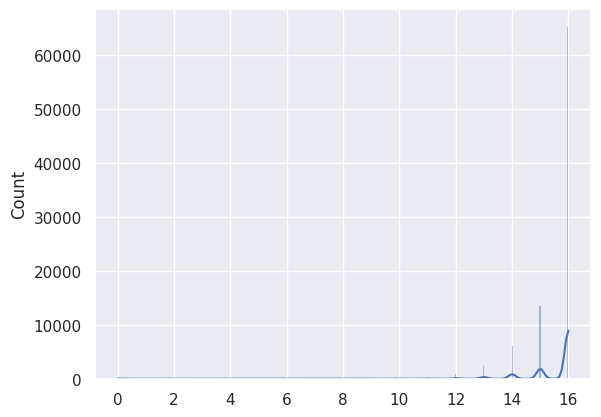

In [25]:
# look at the count of accuracy

listAccuracy = df["accuracy"].tolist()

sns.histplot(listAccuracy, kde=True)
plt.show()